In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Saving emissioni-co2-globali-per-paese-1950-2024.csv to emissioni-co2-globali-per-paese-1950-2024 (1).csv
Dataset loaded successfully!
Dataset shape: (14925, 10)

Column names:
['country', 'year', 'iso_code', 'co2', 'co2_per_capita', 'coal_co2', 'oil_co2', 'gas_co2', 'cement_co2', 'consumption_co2']

First 5 rows:


,country,year,iso_code,co2,co2_per_capita,coal_co2,oil_co2,gas_co2,cement_co2,consumption_co2
0,Afghanistan,1950,AFG,0.084272,0.010837,0.021068,0.063204,0.0,0.0,NaN
1,Afghanistan,1951,AFG,0.091600,0.011625,0.025648,0.065952,0.0,0.0,NaN
2,Afghanistan,1952,AFG,0.091600,0.011468,0.031708,0.059892,0.0,0.0,NaN
3,Afghanistan,1953,AFG,0.106256,0.013123,0.037949,0.068307,0.0,0.0,NaN
4,Afghanistan,1954,AFG,0.106256,0.012945,0.042502,0.063754,0.0,0.0,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14925 entries, 0 to 14924
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          14925 non-null  object 
 1   year             14925 non-null  int64  
 2   iso_code         14925 non-null  object 
 3   co2              14086 non-null  float64
 4   co2_per_capita   14086 non-null  float64
 5   coal_co2         10052 non-null  float64
 6   oil_co2          14026 non-null  float64
 7   gas_co2          7765 non-null   float64
 8   cement_co2       13810 non-null  float64
 9   consumption_co2  4064 non-null   float64
dtypes: float64(7), int64(1), object(2)
memory usage: 1.1+ MB

Missing values:
country                0
year                   0
iso_code               0
co2                  839
co2_per_capita       839
coal_co2            4873
oil_co2              899
gas_co2             7160
cement_co2          1115
consumption_c

In [ ]:
# 1. Check the year range
print("Year range:", df["year"].min(), "-", df["year"].max())

# 2. Check the number of unique countries
print("Unique countries:", df["country"].nunique())

# 3. Check duplicate country-year records
print("Duplicate country-year records:",
      df.duplicated(subset=["country", "year"]).sum())

# 4. Check missing CO2 values by year
print("\nMissing CO2 values by year:")
print(df.groupby("year")["co2"].apply(lambda x: x.isna().sum()).tail(15))

# 5. Check missing values as percentages
print("\nMissing value percentages:")
print((df.isnull().mean() * 100).round(2))

Year range: 1950 - 2024
Unique countries: 199
Duplicate country-year records: 0

Missing CO2 values by year:
year
2010    3
2011    3
2012    3
2013    3
2014    3
2015    3
2016    3
2017    3
2018    3
2019    3
2020    3
2021    3
2022    3
2023    3
2024    3
Name: co2, dtype: int64

Missing value percentages:
country             0.00
year                0.00
iso_code            0.00
co2                 5.62
co2_per_capita      5.62
coal_co2           32.65
oil_co2             6.02
gas_co2            47.97
cement_co2          7.47
consumption_co2    72.77
dtype: float64


In [ ]:
# Display all unique country names
countries = sorted(df["country"].unique())

print("Total unique entries:", len(countries))
print("\nCountry names:\n")

for country in countries:
    print(country)

Total unique entries: 199

Country names:

Afghanistan
Albania
Algeria
Andorra
Angola
Antigua and Barbuda
Argentina
Armenia
Australia
Austria
Azerbaijan
Bahamas
Bahrain
Bangladesh
Barbados
Belarus
Belgium
Belize
Benin
Bhutan
Bolivia
Bosnia and Herzegovina
Botswana
Brazil
Brunei
Bulgaria
Burkina Faso
Burundi
Cambodia
Cameroon
Canada
Cape Verde
Central African Republic
Chad
Chile
China
Colombia
Comoros
Congo
Costa Rica
Cote d'Ivoire
Croatia
Cuba
Cyprus
Czechia
Democratic Republic of Congo
Denmark
Djibouti
Dominica
Dominican Republic
East Timor
Ecuador
Egypt
El Salvador
Equatorial Guinea
Eritrea
Estonia
Eswatini
Ethiopia
Fiji
Finland
France
Gabon
Gambia
Georgia
Germany
Ghana
Greece
Grenada
Guatemala
Guinea
Guinea-Bissau
Guyana
Haiti
Honduras
Hong Kong
Hungary
Iceland
India
Indonesia
Iran
Iraq
Ireland
Israel
Italy
Jamaica
Japan
Jordan
Kazakhstan
Kenya
Kiribati
Kosovo
Kuwait
Kyrgyzstan
Laos
Latvia
Lebanon
Lesotho
Liberia
Libya
Liechtenstein
Lithuania
Luxembourg
Macao
Madagascar
Malawi
Malay

In [ ]:
# Count missing CO2 values for each country
missing_co2 = df.groupby("country")["co2"].apply(
    lambda x: x.isna().sum()
)

# Display countries with missing CO2 values
missing_co2 = missing_co2[missing_co2 > 0].sort_values(
    ascending=False
)

print("Countries with missing CO2 values:")
print(missing_co2)

print("\nTotal countries with missing values:", len(missing_co2))
print("Total missing CO2 records:", df["co2"].isna().sum())

Countries with missing CO2 values:
country
Vatican                  75
San Marino               75
Monaco                   75
East Timor               44
Kosovo                   44
Eritrea                  44
Micronesia (country)     42
Marshall Islands         42
Namibia                  41
Andorra                  40
Tuvalu                   40
Lesotho                  40
Palestine                40
Botswana                 22
Maldives                 21
Bhutan                   20
Oman                     14
Nauru                    14
Seychelles               13
Vanuatu                  12
Kiribati                 11
Mauritania                9
United Arab Emirates      9
Comoros                   9
Liechtenstein             9
Mali                      9
Cambodia                  5
Palau                     5
Laos                      5
Macao                     4
Solomon Islands           2
Eswatini                  2
Dominica                  1
Sao Tome and Principe     1
Name:

In [ ]:
# Step 5: Check annual CO2 data completeness

# Count valid CO2 observations for each country
valid_counts = df.groupby("country")["co2"].count()

# Keep countries with at least 70 valid observations
selected_countries = valid_counts[valid_counts >= 70].index.tolist()

# Filter the dataset
df_selected = df[df["country"].isin(selected_countries)].copy()

print("Original number of countries:", df["country"].nunique())
print("Selected countries:", len(selected_countries))
print("Excluded countries:", df["country"].nunique() - len(selected_countries))

print("\nSelected dataset shape:", df_selected.shape)

print("\nCountries excluded:")
print(sorted(set(df["country"].unique()) - set(selected_countries)))

Original number of countries: 199
Selected countries: 173
Excluded countries: 26

Selected dataset shape: (12975, 10)

Countries excluded:
['Andorra', 'Bhutan', 'Botswana', 'Comoros', 'East Timor', 'Eritrea', 'Kiribati', 'Kosovo', 'Lesotho', 'Liechtenstein', 'Maldives', 'Mali', 'Marshall Islands', 'Mauritania', 'Micronesia (country)', 'Monaco', 'Namibia', 'Nauru', 'Oman', 'Palestine', 'San Marino', 'Seychelles', 'Tuvalu', 'United Arab Emirates', 'Vanuatu', 'Vatican']


In [ ]:
# Step 6: Create country-by-year emission matrix

# Arrange countries as rows and years as columns
co2_matrix = df_selected.pivot(
    index="country",
    columns="year",
    values="co2"
)

# Ensure years are ordered from 1950 to 2024
co2_matrix = co2_matrix.reindex(columns=range(1950, 2025))

print("Country-by-year matrix shape:", co2_matrix.shape)

print("\nFirst 5 countries and first 10 years:")
display(co2_matrix.iloc[:5, :10])

print("\nMissing values in the matrix:", co2_matrix.isna().sum().sum())

print("\nCountries with remaining missing values:",
      co2_matrix.isna().any(axis=1).sum())

Country-by-year matrix shape: (173, 75)

First 5 countries and first 10 years:


year,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959
country,,,,,,,,,,
Afghanistan,0.084272,0.091600,0.091600,0.106256,0.106256,0.153888,0.183200,0.293120,0.329760,0.384571
Albania,0.296725,0.402981,0.373669,0.413973,0.501909,0.663006,0.838789,1.505607,1.201465,1.443319
Algeria,3.783605,4.131179,3.889207,3.999006,4.152302,4.606578,4.995053,5.537086,5.214119,5.657017
Angola,0.186864,0.249152,0.311440,0.274681,0.347904,0.413735,0.501611,0.618681,0.592885,0.618592
Antigua and Barbuda,0.012213,0.019541,0.014656,0.017099,0.012213,0.021984,0.021984,0.021984,0.029312,0.029312



Missing values in the matrix: 25

Countries with remaining missing values: 8


In [ ]:
# Step 7: Fill missing CO2 values using linear interpolation

co2_matrix = co2_matrix.interpolate(
    method="linear",
    axis=1,
    limit_area="inside"
)

# Remove countries with any remaining missing values
co2_matrix = co2_matrix.dropna(axis=0)

print("Matrix shape after handling missing values:", co2_matrix.shape)

print("Remaining missing values:", co2_matrix.isna().sum().sum())

print("Countries retained:", co2_matrix.shape[0])
print("Year features:", co2_matrix.shape[1])

Matrix shape after handling missing values: (166, 75)
Remaining missing values: 0
Countries retained: 166
Year features: 75


In [ ]:
# Step 8: Transform and standardize CO2 emissions

from sklearn.preprocessing import StandardScaler
import numpy as np

# Convert the matrix to a NumPy array
X = co2_matrix.to_numpy(dtype=float)

# Apply log1p transformation
X_log = np.log1p(X)

# Standardize each year's feature across countries
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Original matrix shape:", X.shape)
print("Transformed matrix shape:", X_log.shape)
print("Standardized matrix shape:", X_scaled.shape)

print("\nStandardized feature mean (first 5 years):")
print(np.round(X_scaled.mean(axis=0)[:5], 4))

print("\nStandardized feature standard deviation (first 5 years):")
print(np.round(X_scaled.std(axis=0)[:5], 4))

print("\nAny NaN values:", np.isnan(X_scaled).any())
print("Any infinite values:", np.isinf(X_scaled).any())

Original matrix shape: (166, 75)
Transformed matrix shape: (166, 75)
Standardized matrix shape: (166, 75)

Standardized feature mean (first 5 years):
[ 0. -0. -0. -0. -0.]

Standardized feature standard deviation (first 5 years):
[1. 1. 1. 1. 1.]

Any NaN values: False
Any infinite values: False


In [ ]:
# Step 9: Import libraries and initialize SOM parameters

import numpy as np
import matplotlib.pyplot as plt

# SOM grid dimensions
GRID_ROWS = 7
GRID_COLS = 7

# Number of input features (years)
INPUT_DIM = X_scaled.shape[1]

# Training parameters
MAX_EPOCHS = 100
INITIAL_SIGMA = 3.0
FINAL_SIGMA = 0.5

# Reproducibility
np.random.seed(42)

# Initialize neuron weight vectors using random samples
sample_indices = np.random.choice(
    X_scaled.shape[0],
    size=GRID_ROWS * GRID_COLS,
    replace=True
)

weights = X_scaled[sample_indices].reshape(
    GRID_ROWS, GRID_COLS, INPUT_DIM
).copy()

print("SOM initialized successfully!")
print("Grid size:", GRID_ROWS, "x", GRID_COLS)
print("Total neurons:", GRID_ROWS * GRID_COLS)
print("Input features per neuron:", INPUT_DIM)
print("Weight tensor shape:", weights.shape)
print("Maximum epochs:", MAX_EPOCHS)

SOM initialized successfully!
Grid size: 7 x 7
Total neurons: 49
Input features per neuron: 75
Weight tensor shape: (7, 7, 75)
Maximum epochs: 100


In [ ]:
# Step 10: Implement Best Matching Unit (BMU) calculation

def find_bmu(sample, weights):
    """
    Find the neuron whose weight vector is closest to the input sample.
    Returns the BMU's (row, column) coordinates.
    """
    distances = np.linalg.norm(weights - sample, axis=2)
    bmu_index = np.unravel_index(np.argmin(distances), distances.shape)
    return bmu_index


# Test BMU calculation on the first country
first_country = co2_matrix.index[0]
first_sample = X_scaled[0]

bmu = find_bmu(first_sample, weights)

print("Test country:", first_country)
print("Best Matching Unit:", bmu)
print("BMU row:", bmu[0])
print("BMU column:", bmu[1])
print("Distance to BMU:", round(
    np.linalg.norm(weights[bmu] - first_sample), 4
))

Test country: Afghanistan
Best Matching Unit: (np.int64(4), np.int64(2))
BMU row: 4
BMU column: 2
Distance to BMU: 1.7225


In [ ]:
# Step 11: Train SOM using Batch Competitive Learning

def train_som_batch(X, weights, max_epochs=100,
                    initial_sigma=3.0, final_sigma=0.5):

    rows, cols, input_dim = weights.shape
    trained_weights = weights.copy()
    history = []

    # Coordinates of neurons on the grid
    grid_coords = np.array([
        (r, c)
        for r in range(rows)
        for c in range(cols)
    ])

    # Squared distances between neurons on the grid
    grid_dist_sq = np.sum(
        (grid_coords[:, None, :] - grid_coords[None, :, :]) ** 2,
        axis=2
    )

    for epoch in range(max_epochs):

        # Gradually reduce the neighborhood radius
        progress = epoch / max(1, max_epochs - 1)
        sigma = initial_sigma * (
            final_sigma / initial_sigma
        ) ** progress

        # Find each country's BMU
        flat_weights = trained_weights.reshape(-1, input_dim)

        distances = np.linalg.norm(
            X[:, None, :] - flat_weights[None, :, :],
            axis=2
        )

        bmu_indices = np.argmin(distances, axis=1)

        # Batch neighborhood influence matrix
        neighborhood = np.exp(
            -grid_dist_sq / (2 * sigma ** 2)
        )

        # Calculate updated weights using all countries together
        influence = neighborhood[:, bmu_indices]

        numerator = influence @ X
        denominator = influence.sum(axis=1, keepdims=True)

        updated_weights = numerator / np.maximum(
            denominator, 1e-12
        )

        trained_weights = updated_weights.reshape(
            rows, cols, input_dim
        )

        # Quantization error after the update
        flat_weights = trained_weights.reshape(-1, input_dim)

        final_distances = np.linalg.norm(
            X[:, None, :] - flat_weights[None, :, :],
            axis=2
        )

        quantization_error = np.mean(
            np.min(final_distances, axis=1)
        )

        history.append(quantization_error)

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1}/{max_epochs} | "
                f"Sigma: {sigma:.3f} | "
                f"Quantization Error: {quantization_error:.4f}"
            )

    return trained_weights, history


# Train the SOM
weights, training_history = train_som_batch(
    X_scaled,
    weights,
    max_epochs=MAX_EPOCHS,
    initial_sigma=INITIAL_SIGMA,
    final_sigma=FINAL_SIGMA
)

print("\nSOM training completed!")
print("Final weight shape:", weights.shape)
print("Initial quantization error:", round(training_history[0], 4))
print("Final quantization error:", round(training_history[-1], 4))

Epoch 20/100 | Sigma: 2.127 | Quantization Error: 2.1446
Epoch 40/100 | Sigma: 1.481 | Quantization Error: 1.6564
Epoch 60/100 | Sigma: 1.031 | Quantization Error: 1.3862
Epoch 80/100 | Sigma: 0.718 | Quantization Error: 1.2177
Epoch 100/100 | Sigma: 0.500 | Quantization Error: 1.0900

SOM training completed!
Final weight shape: (7, 7, 75)
Initial quantization error: 5.4547
Final quantization error: 1.09


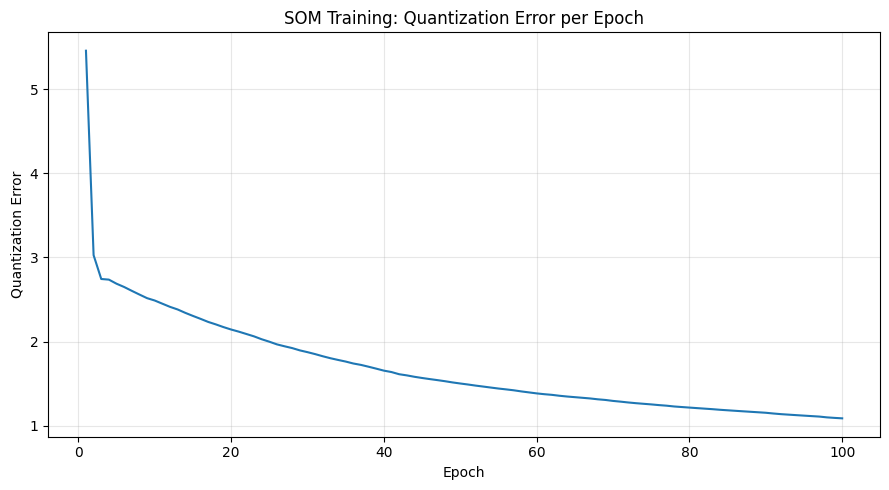

Initial quantization error: 5.4547
Final quantization error: 1.09
Error reduction: 80.02 %


In [ ]:
# Step 12: Visualize SOM training progress

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, MAX_EPOCHS + 1),
    training_history
)

plt.title("SOM Training: Quantization Error per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Quantization Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Initial quantization error:", round(training_history[0], 4))
print("Final quantization error:", round(training_history[-1], 4))

reduction = (
    (training_history[0] - training_history[-1])
    / training_history[0]
) * 100

print("Error reduction:", round(reduction, 2), "%")

In [ ]:
# Step 13: Assign each country to its trained SOM neuron

country_assignments = []

for i, country in enumerate(co2_matrix.index):
    bmu = find_bmu(X_scaled[i], weights)

    country_assignments.append({
        "Country": country,
        "SOM_Row": int(bmu[0]),
        "SOM_Column": int(bmu[1])
    })

import pandas as pd

som_results = pd.DataFrame(country_assignments)

# Create a unique neuron label for each country
som_results["Neuron"] = (
    "N" +
    som_results["SOM_Row"].astype(str) +
    "_" +
    som_results["SOM_Column"].astype(str)
)

print("Country assignments completed!")
print("Total countries mapped:", len(som_results))
print("Unique neurons occupied:", som_results["Neuron"].nunique())

print("\nFirst 15 country assignments:")
print(som_results.head(15).to_string(index=False))

print("\nCountries per neuron (most populated first):")
print(
    som_results["Neuron"]
    .value_counts()
    .head(10)
    .to_string()
)

Country assignments completed!
Total countries mapped: 166
Unique neurons occupied: 47

First 15 country assignments:
            Country  SOM_Row  SOM_Column Neuron
        Afghanistan        4           1   N4_1
            Albania        6           3   N6_3
            Algeria        1           3   N1_3
             Angola        2           1   N2_1
Antigua and Barbuda        6           0   N6_0
          Argentina        2           5   N2_5
            Armenia        5           3   N5_3
          Australia        1           5   N1_5
            Austria        3           6   N3_6
         Azerbaijan        4           5   N4_5
            Bahamas        6           2   N6_2
            Bahrain        1           0   N1_0
         Bangladesh        0           0   N0_0
           Barbados        6           1   N6_1
            Belarus        3           6   N3_6

Countries per neuron (most populated first):
Neuron
N6_0    14
N6_1     8
N1_5     7
N3_0     7
N1_3     6
N4_0  

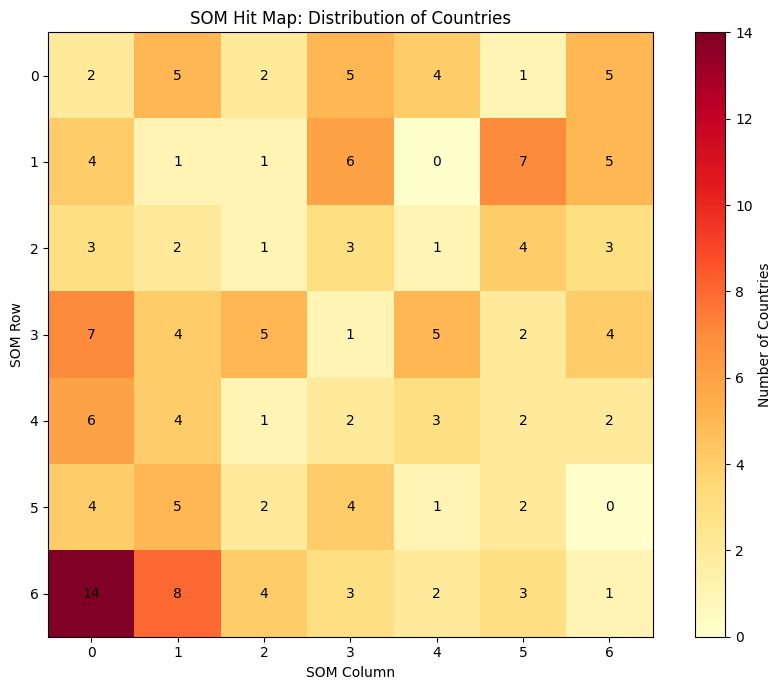

Total countries represented: 166
Empty neurons: 2
Most populated neuron: N6_0
Maximum countries in one neuron: 14


In [ ]:
# Step 14: Plot the SOM hit map

hit_map = np.zeros((GRID_ROWS, GRID_COLS), dtype=int)

for _, row in som_results.iterrows():
    r = int(row["SOM_Row"])
    c = int(row["SOM_Column"])
    hit_map[r, c] += 1

plt.figure(figsize=(9, 7))

plt.imshow(hit_map, cmap="YlOrRd", interpolation="nearest")
plt.colorbar(label="Number of Countries")

plt.xticks(range(GRID_COLS))
plt.yticks(range(GRID_ROWS))
plt.xlabel("SOM Column")
plt.ylabel("SOM Row")
plt.title("SOM Hit Map: Distribution of Countries")

# Display country counts in each cell
for r in range(GRID_ROWS):
    for c in range(GRID_COLS):
        plt.text(
            c, r, str(hit_map[r, c]),
            ha="center", va="center",
            color="black", fontsize=10
        )

plt.tight_layout()
plt.show()

print("Total countries represented:", hit_map.sum())
print("Empty neurons:", np.sum(hit_map == 0))
print("Most populated neuron:", som_results["Neuron"].value_counts().idxmax())
print("Maximum countries in one neuron:", hit_map.max())

/tmp/ipykernel_1447/3010587211.py:21: RuntimeWarning: Mean of empty slice
  mean_profiles = np.nanmean(neuron_profiles, axis=2)


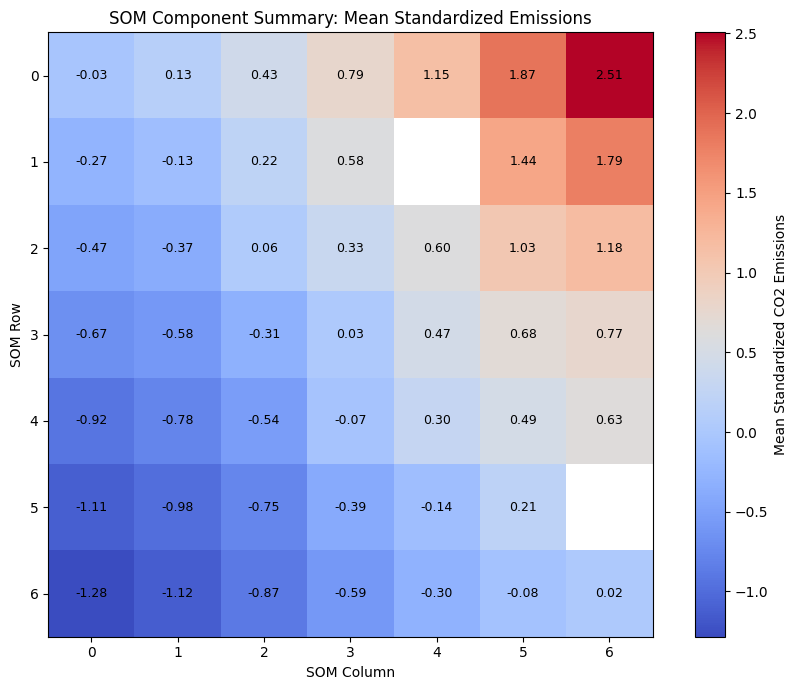

Mean profile matrix shape: (7, 7)
Highest mean-profile neuron: (np.int64(0), np.int64(6))
Lowest mean-profile neuron: (np.int64(6), np.int64(0))


In [ ]:
# Step 15: Calculate average emission patterns for each neuron

neuron_profiles = np.zeros((GRID_ROWS, GRID_COLS, X_scaled.shape[1]))

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):

        # Find countries assigned to this neuron
        mask = (
            (som_results["SOM_Row"].to_numpy() == r) &
            (som_results["SOM_Column"].to_numpy() == c)
        )

        # Average their standardized CO2 emission patterns
        if mask.sum() > 0:
            neuron_profiles[r, c] = X_scaled[mask].mean(axis=0)
        else:
            neuron_profiles[r, c] = np.nan

# Average across all years to summarize each neuron's profile
mean_profiles = np.nanmean(neuron_profiles, axis=2)

plt.figure(figsize=(9, 7))

plt.imshow(mean_profiles, cmap="coolwarm", interpolation="nearest")
plt.colorbar(label="Mean Standardized CO2 Emissions")

plt.xticks(range(GRID_COLS))
plt.yticks(range(GRID_ROWS))
plt.xlabel("SOM Column")
plt.ylabel("SOM Row")
plt.title("SOM Component Summary: Mean Standardized Emissions")

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):
        if not np.isnan(mean_profiles[r, c]):
            plt.text(
                c, r, f"{mean_profiles[r, c]:.2f}",
                ha="center", va="center",
                color="black", fontsize=9
            )

plt.tight_layout()
plt.show()

print("Mean profile matrix shape:", mean_profiles.shape)
print("Highest mean-profile neuron:",
      np.unravel_index(np.nanargmax(mean_profiles), mean_profiles.shape))
print("Lowest mean-profile neuron:",
      np.unravel_index(np.nanargmin(mean_profiles), mean_profiles.shape))

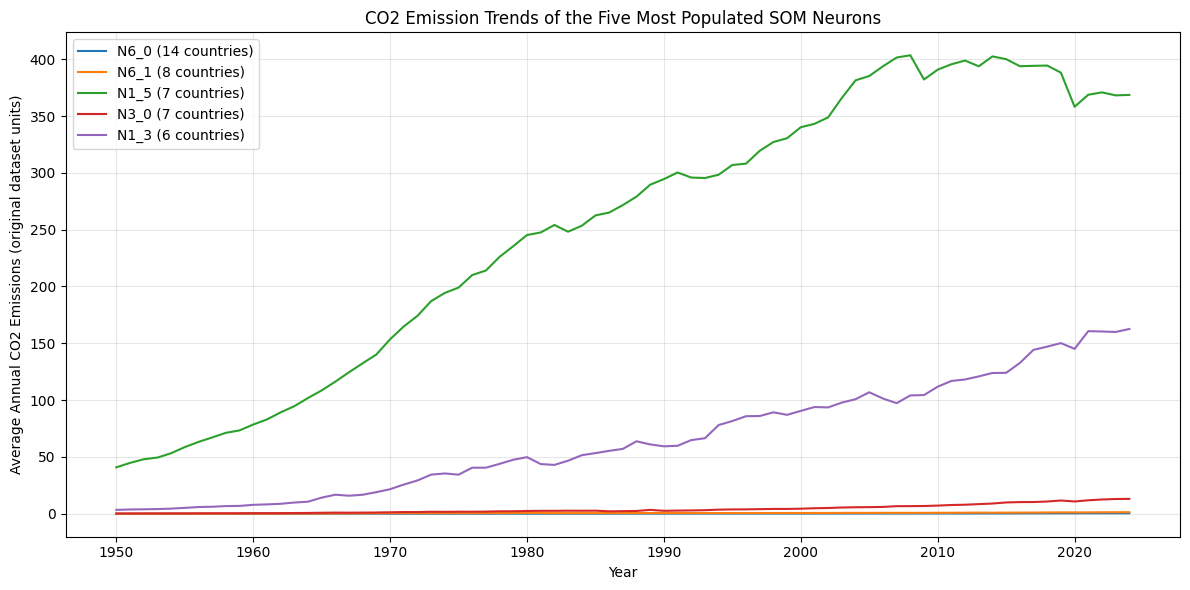

Neurons compared: ['N6_0', 'N6_1', 'N1_5', 'N3_0', 'N1_3']

N6_0: 14 countries
Antigua and Barbuda, Belize, Burundi, Cape Verde, Central African Republic, Djibouti, Gambia, Grenada, Guinea-Bissau, Saint Kitts and Nevis, Saint Lucia, Saint Vincent and the Grenadines, Samoa, Tonga

N6_1: 8 countries
Barbados, Eswatini, Fiji, Liberia, Malawi, Rwanda, Sierra Leone, Somalia

N1_5: 7 countries
Australia, Brazil, Italy, Kazakhstan, Mexico, South Africa, Spain

N3_0: 7 countries
Cameroon, Costa Rica, El Salvador, Ethiopia, Honduras, Senegal, Tanzania

N1_3: 6 countries
Algeria, Greece, Iraq, Nigeria, Pakistan, Philippines


In [ ]:
# Step 16: Compare annual CO2 emission trends across major neurons

# Find the five most populated neurons
top_neurons = som_results["Neuron"].value_counts().head(5).index

plt.figure(figsize=(12, 6))

for neuron in top_neurons:
    countries = som_results.loc[
        som_results["Neuron"] == neuron, "Country"
    ]

    # Average original CO2 emissions for countries in this neuron
    avg_emissions = co2_matrix.loc[countries].mean(axis=0)

    plt.plot(
        co2_matrix.columns,
        avg_emissions,
        label=f"{neuron} ({len(countries)} countries)"
    )

plt.title("CO2 Emission Trends of the Five Most Populated SOM Neurons")
plt.xlabel("Year")
plt.ylabel("Average Annual CO2 Emissions (original dataset units)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Neurons compared:", list(top_neurons))

for neuron in top_neurons:
    countries = som_results.loc[
        som_results["Neuron"] == neuron, "Country"
    ].tolist()

    print(f"\n{neuron}: {len(countries)} countries")
    print(", ".join(countries))

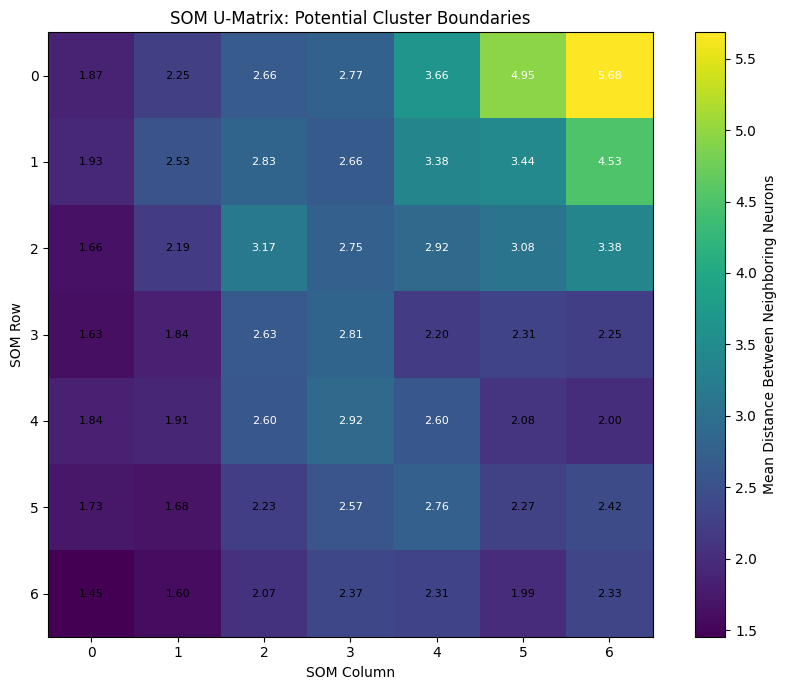

U-Matrix shape: (7, 7)
Mean neighboring-neuron distance: 2.5655
Minimum distance: 1.4534
Maximum distance: 5.685


In [ ]:
# Step 17: Calculate and visualize the SOM U-Matrix

u_matrix = np.zeros((GRID_ROWS, GRID_COLS))

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):
        neighbor_distances = []

        # Check the four direct neighbors
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc

            if 0 <= nr < GRID_ROWS and 0 <= nc < GRID_COLS:
                distance = np.linalg.norm(
                    weights[r, c] - weights[nr, nc]
                )
                neighbor_distances.append(distance)

        u_matrix[r, c] = np.mean(neighbor_distances)

plt.figure(figsize=(9, 7))

plt.imshow(u_matrix, cmap="viridis", interpolation="nearest")
plt.colorbar(label="Mean Distance Between Neighboring Neurons")

plt.xticks(range(GRID_COLS))
plt.yticks(range(GRID_ROWS))
plt.xlabel("SOM Column")
plt.ylabel("SOM Row")
plt.title("SOM U-Matrix: Potential Cluster Boundaries")

for r in range(GRID_ROWS):
    for c in range(GRID_COLS):
        plt.text(
            c, r, f"{u_matrix[r, c]:.2f}",
            ha="center", va="center",
            color="white" if u_matrix[r, c] > u_matrix.mean() else "black",
            fontsize=8
        )

plt.tight_layout()
plt.show()

print("U-Matrix shape:", u_matrix.shape)
print("Mean neighboring-neuron distance:", round(u_matrix.mean(), 4))
print("Minimum distance:", round(u_matrix.min(), 4))
print("Maximum distance:", round(u_matrix.max(), 4))

In [ ]:
# Step 18: Evaluate the optimal number of SOM clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

# Find occupied SOM neurons
occupied_neurons = sorted(
    set(zip(som_results["SOM_Row"], som_results["SOM_Column"]))
)

# Extract trained weight vectors for occupied neurons
neuron_weights = np.array([
    weights[r, c]
    for r, c in occupied_neurons
])

# Store the silhouette scores
cluster_scores = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    neuron_labels = kmeans.fit_predict(neuron_weights)

    # Assign each country the cluster of its SOM neuron
    neuron_to_cluster = {
        neuron: label
        for neuron, label in zip(occupied_neurons, neuron_labels)
    }

    country_labels = [
        neuron_to_cluster[(r, c)]
        for r, c in zip(
            som_results["SOM_Row"],
            som_results["SOM_Column"]
        )
    ]

    score = silhouette_score(X_scaled, country_labels)

    cluster_scores.append({
        "Number of Clusters": k,
        "Silhouette Score": round(score, 4),
        "Inertia": round(kmeans.inertia_, 4)
    })

scores_df = pd.DataFrame(cluster_scores)

print("Cluster Evaluation Results:")
display(scores_df)

best_k = int(
    scores_df.loc[
        scores_df["Silhouette Score"].idxmax(),
        "Number of Clusters"
    ]
)

print("Best candidate number of clusters:", best_k)

Cluster Evaluation Results:


,Number of Clusters,Silhouette Score,Inertia
0,2,0.5519,970.5068
1,3,0.4943,536.8503
2,4,0.4114,368.5456
3,5,0.4010,302.0001
4,6,0.3572,253.3905
5,7,0.3708,197.9681
6,8,0.3650,156.2606


Best candidate number of clusters: 2


In [ ]:
# Step 19: Assign final cluster labels to all countries

from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

# Identify occupied SOM neurons
occupied_neurons = sorted(
    set(zip(som_results["SOM_Row"], som_results["SOM_Column"]))
)

# Get trained weight vectors for occupied neurons
neuron_weights = np.array([
    weights[r, c] for r, c in occupied_neurons
])

# Train KMeans using the selected 2 clusters
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

neuron_labels = final_kmeans.fit_predict(neuron_weights)

# Map each occupied SOM neuron to a cluster
neuron_to_cluster = {
    neuron: label + 1
    for neuron, label in zip(occupied_neurons, neuron_labels)
}

# Assign cluster labels to countries
som_results["Cluster"] = [
    neuron_to_cluster[(r, c)]
    for r, c in zip(
        som_results["SOM_Row"],
        som_results["SOM_Column"]
    )
]

# Display cluster sizes
print("Number of countries in each cluster:")
display(
    som_results["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Countries")
)

# Display countries grouped by cluster
for cluster in sorted(som_results["Cluster"].unique()):
    countries = sorted(
        som_results.loc[
            som_results["Cluster"] == cluster, "Country"
        ].tolist()
    )

    print(f"\nCLUSTER {cluster} ({len(countries)} countries)")
    print(", ".join(countries))

print("\nTotal countries clustered:", som_results["Country"].nunique())

Number of countries in each cluster:


,Cluster,Number of Countries
0,1,65
1,2,101



CLUSTER 1 (65 countries)
Algeria, Argentina, Australia, Austria, Azerbaijan, Belarus, Belgium, Brazil, Bulgaria, Canada, Chile, China, Colombia, Cuba, Czechia, Denmark, Egypt, Finland, France, Germany, Greece, Hungary, India, Indonesia, Iran, Iraq, Ireland, Israel, Italy, Japan, Kazakhstan, Kuwait, Malaysia, Mexico, Netherlands, New Zealand, Nigeria, North Korea, Norway, Pakistan, Peru, Philippines, Poland, Portugal, Romania, Russia, Saudi Arabia, Serbia, Singapore, Slovakia, South Africa, South Korea, Spain, Sweden, Switzerland, Taiwan, Thailand, Turkey, Turkmenistan, Ukraine, United Kingdom, United States, Uzbekistan, Venezuela, Vietnam

CLUSTER 2 (101 countries)
Afghanistan, Albania, Angola, Antigua and Barbuda, Armenia, Bahamas, Bahrain, Bangladesh, Barbados, Belize, Benin, Bolivia, Bosnia and Herzegovina, Brunei, Burkina Faso, Burundi, Cameroon, Cape Verde, Central African Republic, Chad, Congo, Costa Rica, Cote d'Ivoire, Croatia, Cyprus, Democratic Republic of Congo, Djibouti, D

Average CO2 emissions per country by year:


,Year,Cluster 1 Average CO2,Cluster 2 Average CO2
0,1950,87.702959,0.903401
1,1951,94.089895,0.972873
2,1952,95.312729,1.057172
3,1953,97.963868,1.101368
4,1954,99.761825,1.234049
5,1955,109.276680,1.371423
6,1956,116.241474,1.483943
7,1957,119.786360,1.606136
8,1958,123.578641,1.631627
9,1959,130.006107,1.746893


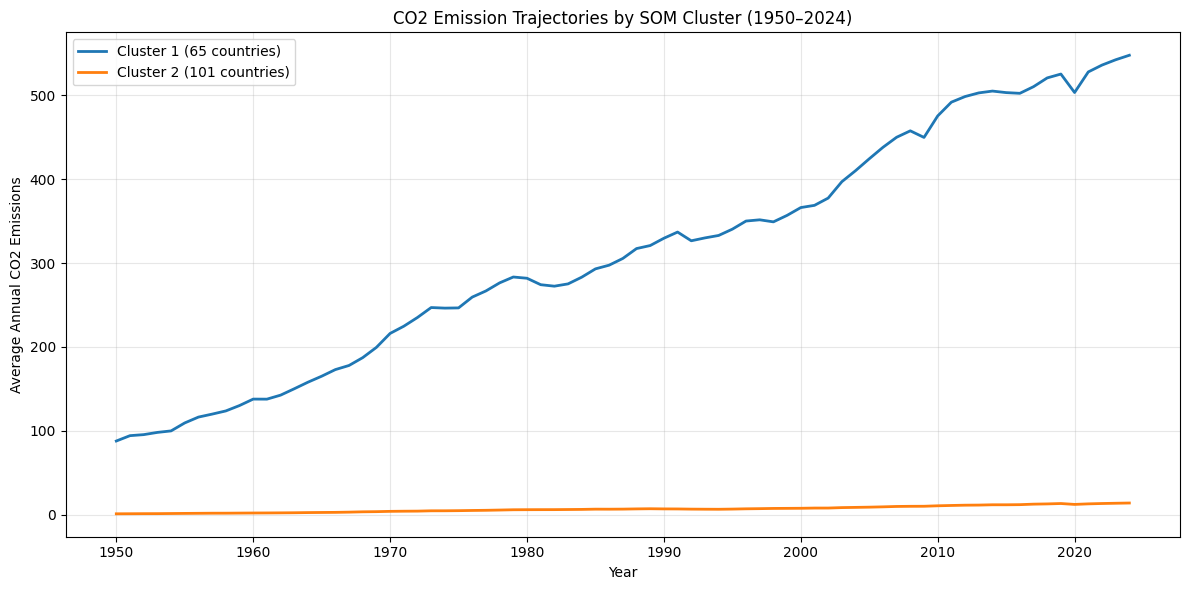


Cluster emission summary:


,Cluster,Countries,Mean Annual CO2 per Country,Maximum Annual CO2 per Country
0,1,65,311.440,12289.037
1,2,101,6.461,125.812


In [ ]:
# Step 20: Compare CO2 emission profiles of the two clusters

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Get the countries belonging to each cluster
cluster_1_countries = som_results.loc[
    som_results["Cluster"] == 1, "Country"
].tolist()

cluster_2_countries = som_results.loc[
    som_results["Cluster"] == 2, "Country"
].tolist()

# Calculate average annual CO2 emissions per country
cluster_1_profile = co2_matrix.loc[cluster_1_countries].mean(axis=0)
cluster_2_profile = co2_matrix.loc[cluster_2_countries].mean(axis=0)

# Create a comparison table
profile_comparison = pd.DataFrame({
    "Year": co2_matrix.columns,
    "Cluster 1 Average CO2": cluster_1_profile.values,
    "Cluster 2 Average CO2": cluster_2_profile.values
})

print("Average CO2 emissions per country by year:")
display(profile_comparison.head(10))

# Plot the annual emission trajectories
plt.figure(figsize=(12, 6))

plt.plot(
    profile_comparison["Year"],
    profile_comparison["Cluster 1 Average CO2"],
    label=f"Cluster 1 ({len(cluster_1_countries)} countries)",
    linewidth=2
)

plt.plot(
    profile_comparison["Year"],
    profile_comparison["Cluster 2 Average CO2"],
    label=f"Cluster 2 ({len(cluster_2_countries)} countries)",
    linewidth=2
)

plt.xlabel("Year")
plt.ylabel("Average Annual CO2 Emissions")
plt.title("CO2 Emission Trajectories by SOM Cluster (1950–2024)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Summarize the emission profiles across all years
summary = pd.DataFrame({
    "Cluster": [1, 2],
    "Countries": [len(cluster_1_countries), len(cluster_2_countries)],
    "Mean Annual CO2 per Country": [
        co2_matrix.loc[cluster_1_countries].to_numpy().mean(),
        co2_matrix.loc[cluster_2_countries].to_numpy().mean()
    ],
    "Maximum Annual CO2 per Country": [
        co2_matrix.loc[cluster_1_countries].to_numpy().max(),
        co2_matrix.loc[cluster_2_countries].to_numpy().max()
    ]
})

print("\nCluster emission summary:")
display(summary.round(3))

Average annual emissions by source and cluster:


,coal_co2,oil_co2,gas_co2,cement_co2
Cluster,,,,
1,134.570,109.770,59.487,9.50
2,1.752,3.568,3.036,0.29


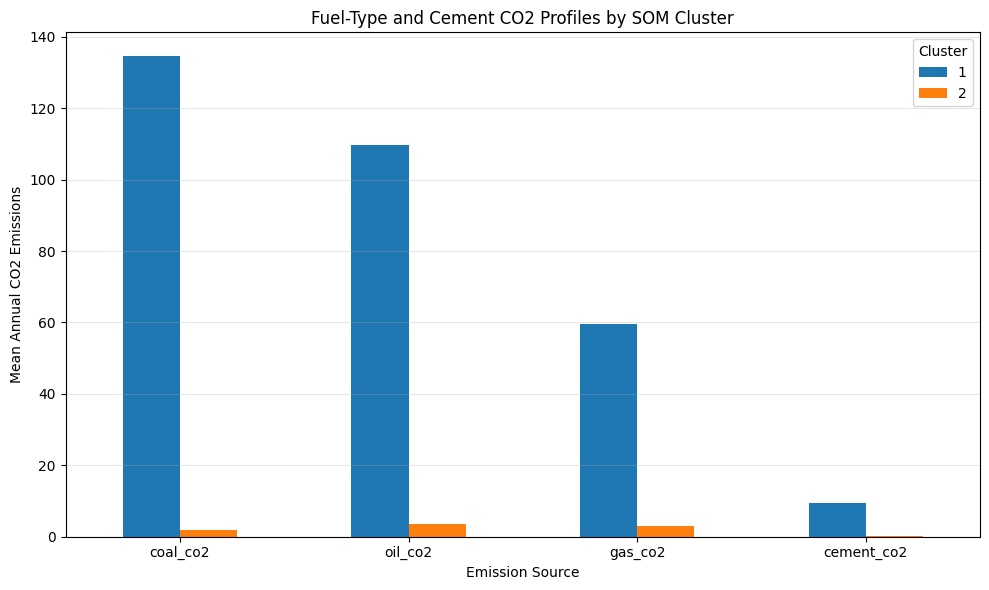


Total mean emissions from the listed sources:


,Total of Listed Sources
Cluster,
1,313.327
2,8.646


In [ ]:
# Step 21: Compare fuel-type composition across SOM clusters

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Fuel and industrial emission columns
fuel_columns = [
    "coal_co2",
    "oil_co2",
    "gas_co2",
    "cement_co2"
]

# Keep country-year rows for the 166 selected countries
df_clustered = df[
    df["country"].isin(som_results["Country"])
].merge(
    som_results[["Country", "Cluster"]],
    left_on="country",
    right_on="Country",
    how="inner"
)

# Calculate average emissions by cluster and source
fuel_profile = (
    df_clustered
    .groupby("Cluster")[fuel_columns]
    .mean()
)

print("Average annual emissions by source and cluster:")
display(fuel_profile.round(3))

# Plot the source comparison
fuel_profile.T.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fuel-Type and Cement CO2 Profiles by SOM Cluster")
plt.xlabel("Emission Source")
plt.ylabel("Mean Annual CO2 Emissions")
plt.xticks(rotation=0)
plt.legend(title="Cluster")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Compare total average emissions across the selected sources
fuel_profile["Total of Listed Sources"] = fuel_profile.sum(axis=1)

print("\nTotal mean emissions from the listed sources:")
display(
    fuel_profile[["Total of Listed Sources"]].round(3)
)

In [ ]:
# Step 22: Compare SOM clustering with K-Means baseline

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd
import numpy as np

# SOM cluster labels
som_labels = som_results.sort_values("Country")["Cluster"].to_numpy()

# Keep country features in the same alphabetical order
sorted_countries = sorted(co2_matrix.index)

X_baseline = np.array([
    X_scaled[list(co2_matrix.index).index(country)]
    for country in sorted_countries
])

# Reorder SOM labels to match the feature matrix
som_labels_aligned = (
    som_results
    .set_index("Country")
    .loc[sorted_countries, "Cluster"]
    .to_numpy()
)

# Baseline: K-Means directly on country trajectories
baseline = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

baseline_labels = baseline.fit_predict(X_baseline)

# Evaluate both approaches
som_silhouette = silhouette_score(
    X_baseline,
    som_labels_aligned
)

kmeans_silhouette = silhouette_score(
    X_baseline,
    baseline_labels
)

comparison = pd.DataFrame({
    "Method": ["SOM + K-Means on neurons", "K-Means baseline"],
    "Number of Clusters": [2, 2],
    "Silhouette Score": [
        round(som_silhouette, 4),
        round(kmeans_silhouette, 4)
    ]
})

print("Clustering method comparison:")
display(comparison)

print(
    "\nAdjusted Rand Index between SOM-based clusters and baseline:",
    round(
        adjusted_rand_score(
            som_labels_aligned,
            baseline_labels
        ),
        4
    )
)

print("\nBaseline cluster sizes:")
display(
    pd.Series(baseline_labels + 1, name="Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Number of Countries")
)

Clustering method comparison:


,Method,Number of Clusters,Silhouette Score
0,SOM + K-Means on neurons,2,0.5519
1,K-Means baseline,2,0.5545



Adjusted Rand Index between SOM-based clusters and baseline: 0.8597

Baseline cluster sizes:


,Cluster,Number of Countries
0,1,95
1,2,71


In [ ]:
# Step 23: Final SOM validation and evaluation summary

import numpy as np
import pandas as pd

# Calculate final quantization error directly
distances = []

for i in range(X_scaled.shape[0]):
    bmu = find_bmu(X_scaled[i], weights)
    distance = np.linalg.norm(
        X_scaled[i] - weights[bmu[0], bmu[1]]
    )
    distances.append(distance)

final_qe = float(np.mean(distances))

# Validate assignments
total_countries = som_results["Country"].nunique()
missing_clusters = int(som_results["Cluster"].isna().sum())
cluster_count = int(som_results["Cluster"].nunique())

# Calculate training improvement
initial_qe = float(training_history[0])
qe_reduction = (
    (initial_qe - final_qe) / initial_qe
) * 100

# Display final evaluation
validation = pd.DataFrame({
    "Metric": [
        "Countries included",
        "Years analyzed",
        "SOM map dimensions",
        "Occupied neurons",
        "Final number of clusters",
        "Initial quantization error",
        "Final quantization error",
        "Quantization error reduction",
        "SOM silhouette score",
        "K-Means baseline silhouette score",
        "Adjusted Rand Index",
        "Countries without cluster assignment"
    ],
    "Value": [
        total_countries,
        "1950–2024",
        f"{GRID_ROWS} × {GRID_COLS}",
        len(occupied_neurons),
        cluster_count,
        round(initial_qe, 4),
        round(final_qe, 4),
        f"{qe_reduction:.2f}%",
        round(som_silhouette, 4),
        round(kmeans_silhouette, 4),
        round(adjusted_rand_score(
            som_labels_aligned, baseline_labels
        ), 4),
        missing_clusters
    ]
})

display(validation)

print(
    "\nValidation passed:",
    total_countries == 166
    and missing_clusters == 0
    and cluster_count == 2
    and np.isfinite(final_qe)
)

,Metric,Value
0,Countries included,166
1,Years analyzed,1950–2024
2,SOM map dimensions,7 × 7
3,Occupied neurons,47
4,Final number of clusters,2
5,Initial quantization error,5.4547
6,Final quantization error,1.09
7,Quantization error reduction,80.02%
8,SOM silhouette score,0.5519
9,K-Means baseline silhouette score,0.5545



Validation passed: True


In [ ]:
# Step 24: Export final SOM project results

import os
import pandas as pd
import numpy as np

output_dir = "CO2_SOM_Results"
os.makedirs(output_dir, exist_ok=True)

# 1. Country-to-cluster assignments
som_results.sort_values(
    ["Cluster", "Country"]
).to_csv(
    f"{output_dir}/country_cluster_assignments.csv",
    index=False
)

# 2. Annual CO2 trajectories by cluster
profile_comparison.to_csv(
    f"{output_dir}/annual_cluster_emission_profiles.csv",
    index=False
)

# 3. Fuel-type profiles
fuel_profile.to_csv(
    f"{output_dir}/fuel_type_cluster_profiles.csv"
)

# 4. Evaluation metrics
validation.to_csv(
    f"{output_dir}/som_validation_metrics.csv",
    index=False
)

# 5. Baseline comparison
comparison.to_csv(
    f"{output_dir}/baseline_comparison.csv",
    index=False
)

# 6. Training history
pd.DataFrame({
    "Epoch": range(1, len(training_history) + 1),
    "Quantization_Error": training_history
}).to_csv(
    f"{output_dir}/training_history.csv",
    index=False
)

print("Project results saved successfully.")
print("\nFiles created:")

for filename in sorted(os.listdir(output_dir)):
    print("-", filename)

Project results saved successfully.

Files created:
- annual_cluster_emission_profiles.csv
- baseline_comparison.csv
- country_cluster_assignments.csv
- fuel_type_cluster_profiles.csv
- som_validation_metrics.csv
- training_history.csv


In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Split countries into training and testing sets
indices = np.arange(len(X_scaled))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42
)

X_train = X_scaled[train_idx]
X_test = X_scaled[test_idx]

country_names = co2_matrix.index.to_numpy()
train_countries = country_names[train_idx]
test_countries = country_names[test_idx]

print("TRAIN/TEST SPLIT")
print("-" * 35)
print("Total countries:", len(X_scaled))
print("Training countries:", len(X_train))
print("Testing countries:", len(X_test))
print("Training percentage:", round(len(X_train) / len(X_scaled) * 100, 2), "%")
print("Testing percentage:", round(len(X_test) / len(X_scaled) * 100, 2), "%")
print("Missing values in training:", np.isnan(X_train).sum())
print("Missing values in testing:", np.isnan(X_test).sum())
print("Country overlap:", len(set(train_countries) & set(test_countries)))

TRAIN/TEST SPLIT
-----------------------------------
Total countries: 166
Training countries: 132
Testing countries: 34
Training percentage: 79.52 %
Testing percentage: 20.48 %
Missing values in training: 0
Missing values in testing: 0
Country overlap: 0


In [ ]:
import inspect

print(inspect.signature(train_som_batch))
print("\nFunction source code:\n")
print(inspect.getsource(train_som_batch))

(X, weights, max_epochs=100, initial_sigma=3.0, final_sigma=0.5)

Function source code:

def train_som_batch(X, weights, max_epochs=100,
                    initial_sigma=3.0, final_sigma=0.5):

    rows, cols, input_dim = weights.shape
    trained_weights = weights.copy()
    history = []

    # Coordinates of neurons on the grid
    grid_coords = np.array([
        (r, c)
        for r in range(rows)
        for c in range(cols)
    ])

    # Squared distances between neurons on the grid
    grid_dist_sq = np.sum(
        (grid_coords[:, None, :] - grid_coords[None, :, :]) ** 2,
        axis=2
    )

    for epoch in range(max_epochs):

        # Gradually reduce the neighborhood radius
        progress = epoch / max(1, max_epochs - 1)
        sigma = initial_sigma * (
            final_sigma / initial_sigma
        ) ** progress

        # Find each country's BMU
        flat_weights = trained_weights.reshape(-1, input_dim)

        distances = np.linalg.norm(
            X[:, None,

In [ ]:
import numpy as np

# Initialize a new SOM using training data only
np.random.seed(42)

som_rows = 7
som_cols = 7
input_dim = X_train.shape[1]

train_weights = X_train[
    np.random.choice(
        len(X_train),
        som_rows * som_cols,
        replace=True
    )
].reshape(som_rows, som_cols, input_dim)

# Train the SOM using the correct parameter names
train_weights, test_training_history = train_som_batch(
    X_train,
    train_weights,
    max_epochs=100,
    initial_sigma=3.0,
    final_sigma=0.5
)

print("\nTRAINING COMPLETE")
print("-" * 35)
print("Training countries:", len(X_train))
print("Testing countries:", len(X_test))
print("SOM dimensions:", f"{som_rows} x {som_cols}")
print("Weight matrix shape:", train_weights.shape)
print("Training epochs:", len(test_training_history))
print(
    "Final training quantization error:",
    round(float(test_training_history[-1]), 4)
)

Epoch 20/100 | Sigma: 2.127 | Quantization Error: 2.0634
Epoch 40/100 | Sigma: 1.481 | Quantization Error: 1.6059
Epoch 60/100 | Sigma: 1.031 | Quantization Error: 1.3329
Epoch 80/100 | Sigma: 0.718 | Quantization Error: 1.1504
Epoch 100/100 | Sigma: 0.500 | Quantization Error: 0.9973

TRAINING COMPLETE
-----------------------------------
Training countries: 132
Testing countries: 34
SOM dimensions: 7 x 7
Weight matrix shape: (7, 7, 75)
Training epochs: 100
Final training quantization error: 0.9973


In [ ]:
import numpy as np

# Calculate BMU distances without modifying trained weights
test_distances = np.linalg.norm(
    X_test[:, None, None, :] - train_weights[None, :, :, :],
    axis=3
)

# Minimum distance from each test country to its BMU
test_min_distances = np.min(
    test_distances.reshape(len(X_test), -1),
    axis=1
)

# Training quantization error
train_distances = np.linalg.norm(
    X_train[:, None, None, :] - train_weights[None, :, :, :],
    axis=3
)

train_min_distances = np.min(
    train_distances.reshape(len(X_train), -1),
    axis=1
)

train_qe = float(np.mean(train_min_distances))
test_qe = float(np.mean(test_min_distances))

print("HELD-OUT SOM EVALUATION")
print("-" * 40)
print("Training countries:", len(X_train))
print("Testing countries:", len(X_test))
print("Training quantization error:", round(train_qe, 4))
print("Test quantization error:", round(test_qe, 4))

if train_qe > 0:
    print(
        "Test/train QE ratio:",
        round(test_qe / train_qe, 4)
    )

print("\nTest countries with BMU distances:")
for country, distance in zip(test_countries, test_min_distances):
    print(f"{country}: {distance:.4f}")

HELD-OUT SOM EVALUATION
----------------------------------------
Training countries: 132
Testing countries: 34
Training quantization error: 0.9973
Test quantization error: 1.5965
Test/train QE ratio: 1.6008

Test countries with BMU distances:
Mozambique: 1.8077
South Korea: 2.2346
Japan: 3.6212
Georgia: 1.4512
Mongolia: 1.6028
Chad: 0.7690
New Zealand: 1.1557
Kuwait: 2.7957
Vietnam: 2.5788
North Korea: 3.4217
Bosnia and Herzegovina: 1.5322
Djibouti: 0.3111
Belgium: 1.3948
Hong Kong: 1.2410
Burundi: 0.3320
China: 5.6285
Singapore: 1.8331
Fiji: 0.3726
Myanmar: 1.3139
Belize: 0.3357
Italy: 1.9050
Bolivia: 1.2781
Bangladesh: 1.9534
Azerbaijan: 0.9512
Slovakia: 0.7600
Israel: 1.1171
South Africa: 1.1068
Grenada: 0.3937
Gambia: 0.2682
Tajikistan: 1.9862
Chile: 1.5228
Sudan: 1.2409
Qatar: 2.4981
Lebanon: 1.5675


In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Fit K-Means using training countries only
kmeans_test = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

train_kmeans_labels = kmeans_test.fit_predict(X_train)

# Assign unseen test countries to their nearest learned centroid
test_kmeans_labels = kmeans_test.predict(X_test)

# Calculate distances to the nearest centroid
train_centroid_distances = kmeans_test.transform(X_train)
test_centroid_distances = kmeans_test.transform(X_test)

train_kmeans_error = np.mean(
    np.min(train_centroid_distances, axis=1)
)

test_kmeans_error = np.mean(
    np.min(test_centroid_distances, axis=1)
)

# Silhouette score on training data only
train_kmeans_silhouette = silhouette_score(
    X_train,
    train_kmeans_labels
)

print("K-MEANS HELD-OUT BASELINE")
print("-" * 40)
print("Training countries:", len(X_train))
print("Testing countries:", len(X_test))
print("Training mean centroid distance:",
      round(float(train_kmeans_error), 4))
print("Test mean centroid distance:",
      round(float(test_kmeans_error), 4))
print("Training silhouette score:",
      round(float(train_kmeans_silhouette), 4))

print("\nTest cluster distribution:")
unique, counts = np.unique(test_kmeans_labels, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster + 1}: {count} countries")

K-MEANS HELD-OUT BASELINE
----------------------------------------
Training countries: 132
Testing countries: 34
Training mean centroid distance: 4.1463
Test mean centroid distance: 5.3468
Training silhouette score: 0.5816

Test cluster distribution:
Cluster 1: 19 countries
Cluster 2: 15 countries


In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Flatten the trained SOM weights
flat_train_weights = train_weights.reshape(-1, X_train.shape[1])

# Find each training country's best matching neuron
train_bmu_indices = np.argmin(
    np.linalg.norm(
        X_train[:, None, :] - flat_train_weights[None, :, :],
        axis=2
    ),
    axis=1
)

# Identify neurons occupied by training countries
occupied_indices = np.unique(train_bmu_indices)
occupied_weights = flat_train_weights[occupied_indices]

# Cluster occupied neuron weights into two clusters
som_cluster_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
som_cluster_model.fit(occupied_weights)

# Map each occupied neuron to a cluster
neuron_cluster_map = dict(
    zip(occupied_indices, som_cluster_model.labels_)
)

# Assign training countries to SOM clusters
train_som_labels = np.array([
    neuron_cluster_map[idx] for idx in train_bmu_indices
])

# Assign each test country to its nearest SOM neuron
test_bmu_indices = np.argmin(
    np.linalg.norm(
        X_test[:, None, :] - flat_train_weights[None, :, :],
        axis=2
    ),
    axis=1
)

# Assign test countries using the nearest neuron's cluster.
# If the nearest neuron was unoccupied during training, use the
# nearest occupied neuron instead.
test_som_labels = []

for sample, bmu_idx in zip(X_test, test_bmu_indices):
    if bmu_idx in neuron_cluster_map:
        label = neuron_cluster_map[bmu_idx]
    else:
        nearest_occupied_pos = np.argmin(
            np.linalg.norm(occupied_weights - sample, axis=1)
        )
        label = som_cluster_model.labels_[nearest_occupied_pos]

    test_som_labels.append(label)

test_som_labels = np.asarray(test_som_labels)

# Silhouette is defined only when there are 2..n-1 distinct labels
if len(np.unique(test_som_labels)) >= 2:
    test_som_silhouette = silhouette_score(
        X_test,
        test_som_labels
    )
else:
    test_som_silhouette = None

print("SOM TEST CLUSTER EVALUATION")
print("-" * 40)
print("Occupied training neurons:", len(occupied_indices))
print("Training cluster sizes:", np.bincount(train_som_labels))
print("Test cluster sizes:", np.bincount(test_som_labels))
print(
    "Test silhouette score:",
    round(float(test_som_silhouette), 4)
    if test_som_silhouette is not None
    else "Undefined: only one cluster assigned"
)

SOM TEST CLUSTER EVALUATION
----------------------------------------
Occupied training neurons: 46
Training cluster sizes: [52 80]
Test cluster sizes: [14 20]
Test silhouette score: 0.4373


In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# Test labels were predicted using the K-Means model
if len(np.unique(test_kmeans_labels)) >= 2:
    test_kmeans_silhouette = silhouette_score(
        X_test,
        test_kmeans_labels
    )
else:
    test_kmeans_silhouette = None

print("HELD-OUT SILHOUETTE COMPARISON")
print("-" * 40)
print("SOM test silhouette:",
      round(float(test_som_silhouette), 4))
print("K-Means test silhouette:",
      round(float(test_kmeans_silhouette), 4)
      if test_kmeans_silhouette is not None
      else "Undefined")

if test_kmeans_silhouette is not None:
    difference = test_som_silhouette - test_kmeans_silhouette
    print("SOM minus K-Means:",
          round(float(difference), 4))

    if difference > 0:
        print("Higher test silhouette: SOM")
    elif difference < 0:
        print("Higher test silhouette: K-Means")
    else:
        print("Both models have equal test silhouette scores.")

HELD-OUT SILHOUETTE COMPARISON
----------------------------------------
SOM test silhouette: 0.4373
K-Means test silhouette: 0.4395
SOM minus K-Means: -0.0021
Higher test silhouette: K-Means


In [ ]:
import pandas as pd
import os

# Create a final evaluation table
test_results = pd.DataFrame({
    "Metric": [
        "Training Countries",
        "Testing Countries",
        "Training Representation Error",
        "Test Representation Error",
        "Test Silhouette Score",
        "Test Cluster 1 Size",
        "Test Cluster 2 Size"
    ],
    "SOM": [
        len(X_train),
        len(X_test),
        train_qe,
        test_qe,
        test_som_silhouette,
        int(np.sum(test_som_labels == 0)),
        int(np.sum(test_som_labels == 1))
    ],
    "KMeans": [
        len(X_train),
        len(X_test),
        train_kmeans_error,
        test_kmeans_error,
        test_kmeans_silhouette,
        int(np.sum(test_kmeans_labels == 0)),
        int(np.sum(test_kmeans_labels == 1))
    ]
})

os.makedirs("CO2_SOM_Results", exist_ok=True)

test_results.to_csv(
    "CO2_SOM_Results/held_out_evaluation.csv",
    index=False
)

print("HELD-OUT EVALUATION RESULTS")
print(test_results.to_string(index=False))
print("\nSaved: CO2_SOM_Results/held_out_evaluation.csv")

HELD-OUT EVALUATION RESULTS
                       Metric        SOM     KMeans
           Training Countries 132.000000 132.000000
            Testing Countries  34.000000  34.000000
Training Representation Error   0.997346   4.146335
    Test Representation Error   1.596539   5.346814
        Test Silhouette Score   0.437322   0.439464
          Test Cluster 1 Size  14.000000  19.000000
          Test Cluster 2 Size  20.000000  15.000000

Saved: CO2_SOM_Results/held_out_evaluation.csv


In [ ]:
import shutil
import os
from google.colab import files

# Rebuild the ZIP with all current results
zip_path = shutil.make_archive(
    "CO2_SOM_Results",
    "zip",
    root_dir="CO2_SOM_Results"
)

print("UPDATED PROJECT ARCHIVE")
print("-" * 35)

for filename in sorted(os.listdir("CO2_SOM_Results")):
    if filename.endswith(".csv"):
        print("-", filename)

print("\nZIP created:", zip_path)

files.download(zip_path)

UPDATED PROJECT ARCHIVE
-----------------------------------
- annual_cluster_emission_profiles.csv
- baseline_comparison.csv
- country_cluster_assignments.csv
- fuel_type_cluster_profiles.csv
- held_out_evaluation.csv
- som_validation_metrics.csv
- training_history.csv

ZIP created: /content/CO2_SOM_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>